# Tier 3 — Double DQN en LunarLander

Este notebook es una entrada independiente del Tier 1. Comparte los algoritmos de
`agents/` y la ejecución de `experiments/`; no contiene una copia alternativa del agente.

**VS Code:** abre la carpeta del proyecto, selecciona el kernel `.venv\Scripts\python.exe`
y usa **Shift+Enter** o **Ejecutar todo**. Tras actualizar el código, reinicia el kernel.
Las extensiones Python y Jupyter de Microsoft son necesarias.
La instalación de dependencias está documentada en el README.

Los entrenamientos y la animación se activan expresamente en sus celdas. Ejecutar todo
consulta resultados guardados y ejemplos. Si un estudio sigue en curso, se indica como pendiente.

La sección **Mejora: confirmación en las tres semillas** añade la nueva ronda. Los estudios iniciales se conservan identificados como tales.

In [1]:
from pathlib import Path
import sys, json, copy
import numpy as np
import torch
from IPython.display import display, Markdown
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'agents/dqn.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Abre la carpeta completa del proyecto en VS Code.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from experiments.lunarlander import configuration, plan, make_env, train, evaluate
from experiments.ejecutar_tier23 import run
from experiments.cuaderno_lunar import OUTPUT, resumen, figura, discusion, demostrar
from experiments.cuaderno_tier1 import codigo
from agents.dqn import QNetwork, DQNAgent
from agents.replay import ReplayBuffer
from agents.double_dqn import DoubleDQNAgent
from agents.dqn_without_target import DQNWithoutTargetAgent
torch.set_num_threads(1)
torch.manual_seed(123)
CONFIG = configuration()
print('Python:', sys.executable)
print('Resultados iniciales:', OUTPUT)

Python: C:\Users\Harolt\Desktop\Universidad\Sem-02-2026\Agentes\Project 01\.venv\Scripts\python.exe
Resultados iniciales: C:\Users\Harolt\Desktop\Universidad\Sem-02-2026\Agentes\Project 01\results\tier23_lunarlander


## 1. Qué exige Tier 3 a nuestro equipo

Como trabajamos en pareja, realizamos la opción **B: mejoras de DQN** en el mismo entorno
de Tier 2. Implementamos **Double DQN** y lo comparamos con el **DQN base**, con los mismos
parámetros, semillas, presupuesto y evaluación. No añadimos Dueling ni otra extensión.

El baseline es exactamente el mismo resultado de Tier 2, no otro entrenamiento elegido después.

In [2]:
print('Entorno:', CONFIG['environment'])
print('Pasos por modelo:', CONFIG['steps'], '| Semillas:', CONFIG['seeds'])
print('Parámetros comunes:', json.dumps(CONFIG['base'], indent=2))

Entorno: LunarLander-v3
Pasos por modelo: 500000 | Semillas: [42, 43, 44]
Parámetros comunes: {
  "hidden_widths": [
    128,
    128
  ],
  "learning_rate": 0.0005,
  "loss": "smooth_l1",
  "gamma": 0.99,
  "buffer_size": 100000,
  "batch_size": 64,
  "learning_starts": 5000,
  "train_every": 8,
  "gradient_steps": 1,
  "target_sync_every": 2000,
  "epsilon_decay_steps": 150000,
  "epsilon_end": 0.05
}


## 2. DQN frente a Double DQN

En DQN, la red objetivo **elige y valora** la siguiente acción:
\[
y_{DQN}=r+\gamma Q_{target}(s',\arg\max_a Q_{target}(s',a)).
\]

En Double DQN, **online elige** y **target valora**:
\[
y_{Double}=r+\gamma Q_{target}(s',\arg\max_a Q_{online}(s',a)).
\]

En ambos se elimina el futuro cuando terminated=True. La idea busca reducir el sesgo
asociado a elegir máximos de estimaciones imperfectas. **No garantiza mejor recompensa
en todas las tareas o semillas**; eso es lo que comparamos experimentalmente.

In [3]:
codigo(DQNAgent.bootstrap_values)
codigo(DoubleDQNAgent)

def bootstrap_values(self, next_observations):
        """DQN estándar: seleccionar y valorar con la red objetivo."""
        return self.target(next_observations).max(dim=1).values

class DoubleDQNAgent(DQNAgent):
    """La red online elige la acción; target estima su valor.

    El resto del agente y el entrenamiento es compartido con DQN estándar.
    learn() llama este cálculo dentro de torch.no_grad().
    """

    def bootstrap_values(self, next_observations):
        actions = self.online(next_observations).argmax(dim=1, keepdim=True)
        return self.target(next_observations).gather(1, actions).squeeze(1)

## 3. Ejemplo numérico

Online prefiere la acción 0; target prefiere la 1. DQN tomará el valor 7 de target.
Double DQN consultará en target el valor de la acción elegida por online: 2.
Esto cambia el objetivo de aprendizaje, no los motores disponibles.

In [4]:
dqn = DQNAgent(obs_dim=8, n_actions=4, hidden_width=16, gamma=0.9, seed=123)
double = DoubleDQNAgent(obs_dim=8, n_actions=4, hidden_width=16, gamma=0.9, seed=123)
for agent in (dqn, double):
    with torch.no_grad():
        for p in agent.online.parameters(): p.zero_()
        for p in agent.target.parameters(): p.zero_()
        agent.online.layers[-1].bias.copy_(torch.tensor([9., 1., -1., -2.]))
        agent.target.layers[-1].bias.copy_(torch.tensor([2., 7., -1., -2.]))
        future = agent.bootstrap_values(torch.zeros((1, 8))).item()
    print(type(agent).__name__, '| valor futuro:', future, '| objetivo con r=1:', 1 + 0.9*future)

DQNAgent | valor futuro: 7.0 | objetivo con r=1: 7.3
DoubleDQNAgent | valor futuro: 2.0 | objetivo con r=1: 2.8


## 4. Compartimos el resto del código

Usamos la misma red, replay, función de pérdida, optimizador y calendario. Solo cambia
`bootstrap_values`. `learn` calcula el objetivo dentro de no_grad y actualiza online;
target permanece fija hasta la siguiente copia. Los episodios de evaluación no entrenan.

In [5]:
codigo(DQNAgent.learn)
codigo(DQNAgent.sync_target)

def learn(self, batch):
        observations = torch.as_tensor(batch.observations, dtype=torch.float32)
        actions = torch.as_tensor(batch.actions, dtype=torch.int64)
        rewards = torch.as_tensor(batch.rewards, dtype=torch.float32)
        next_observations = torch.as_tensor(batch.next_observations, dtype=torch.float32)
        terminated = torch.as_tensor(batch.terminated, dtype=torch.bool)

        # De todas las salidas Q, comparamos solo la correspondiente a la acción tomada.
        predictions = self.online(observations).gather(1, actions[:, None]).squeeze(1)
        with torch.no_grad():
            next_values = self.bootstrap_values(next_observations)
            # Un corte por tiempo no elimina el valor futuro: solo terminated.
            targets = rewards + self.gamma * (~terminated).float() * next_values

        if self.loss_name == "mse":
            loss = nn.functional.mse_loss(predictions, targets)
        else:
            loss = nn.functional.smooth_l1_loss(predictions, targets)
        self.optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(self.online.parameters(), max_norm=10.0)
        self.optimizer.step()
        return {"loss": float(loss.detach()),
                "predictions_before": predictions.detach().tolist(),
                "targets": targets.tolist()}

def sync_target(self):
        """Actualizar la referencia mediante una copia completa de la red online."""
        self.target.load_state_dict(self.online.state_dict())

In [6]:
codigo(evaluate)

def evaluate(network, config, seed, episodes, evaluation_base=None):
    """Otro entorno y RNG; no consumir estados aleatorios del entrenamiento."""
    evaluator = deepcopy(network).eval()
    base = config["evaluation_base"] if evaluation_base is None else evaluation_base
    rng = np.random.default_rng(base + 500_000 + 1000 * seed)
    env = make_env(config)
    returns = []
    try:
        for episode in range(episodes):
            obs, _ = env.reset(seed=base + 1000 * seed + episode)
            total = 0.0
            while True:
                with torch.inference_mode():
                    scores = evaluator(torch.as_tensor(obs, dtype=torch.float32)).numpy()
                action = int(rng.choice(np.flatnonzero(scores == scores.max())))
                obs, reward, terminated, truncated, _ = env.step(action)
                total += reward
                if terminated or truncated:
                    break
            returns.append(float(total))
    finally:
        env.close()
    return returns

## Ejecutar una prueba corta (opcional)

La prueba usa un modelo pequeño y una semilla para comprobar el recorrido. **No es un
resultado formal** y no pretende alcanzar el objetivo. Se guarda en una carpeta nueva.

In [7]:
EJECUTAR_PRUEBA = False
if EJECUTAR_PRUEBA:
    from datetime import datetime
    prueba = copy.deepcopy(CONFIG)
    prueba.update(steps=2000, eval_every=2000, seeds=[123])
    prueba['base'].update(hidden_widths=[32,32], buffer_size=2000, batch_size=32,
                         learning_starts=128, gradient_steps=1)
    destino = ROOT / 'results/notebook_lunar' / datetime.now().strftime('prueba_%Y%m%d_%H%M%S_%f')
    run(prueba, destino, groups=['base'])
else:
    print('Prueba corta desactivada.')

Prueba corta desactivada.


## Repetir estudios iniciales de Tier 3 (opcional, entrenamiento largo)

Activa la celda solo para volver a entrenar. La carpeta debe ser nueva si cambias parámetros.
Para continuar el protocolo original puedes usar OUTPUT: se reutilizan resultados completos
con el mismo protocolo y se rechaza sobrescribir ejecuciones parciales.

Los estudios formales necesitan al menos tres semillas. Tier 2 comprende seis grupos únicos;
Tier 3 comprende base y Double DQN. Si base ya existe, puede reutilizarse.

Para repetir la nueva comparación usa EJECUTAR_MEJORA en la sección siguiente.

In [8]:
EJECUTAR_TIER3 = False
if EJECUTAR_TIER3:
    from datetime import datetime
    if len(set(CONFIG['seeds'])) < 3:
        raise ValueError('El experimento formal requiere tres semillas independientes.')
    destino = ROOT / 'results/notebook_lunar' / datetime.now().strftime('tier3_%Y%m%d_%H%M%S_%f')
    # Para continuar el mismo protocolo original: destino = OUTPUT
    run(CONFIG, destino, groups=['base', 'double'])
else:
    print('Entrenamiento formal desactivado. Los resultados guardados se consultan abajo.')

Entrenamiento formal desactivado. Los resultados guardados se consultan abajo.


## Mejora: confirmación en las tres semillas

Esta ronda añade entrenamiento y busca estabilidad. Conserva los estudios iniciales
de 500000 pasos que aparecen después. La nueva comparación usa **1000000 pasos**
por modelo para DQN y Double DQN, con parámetros y selección iguales.

La tasa de aprendizaje disminuye al final. Se guarda el modelo con mejor **validación
confirmada en 100 episodios**, además del último modelo. Después se comprueba el elegido
en **dos muestras distintas de 100 episodios** que no participan en la selección.
La meta es ≥200 para cada semilla 42, 43 y 44 en ambas muestras, no solo en la media.

CONFIG_MEJORA controla nuevos entrenamientos. Los resultados leídos pertenecen al
protocolo guardado; editar parámetros no modifica los modelos existentes.

Antes entrenábamos cada ocho pasos y copiábamos target cada 2000: unos 250 ajustes por copia. Ahora entrenamos cada cuatro y copiamos cada 1000, manteniendo esa relación aproximada. El ranking de un hiperparámetro depende de los demás ajustes.

In [9]:
from experiments.cuaderno_mejora import (
    refinement_config, refinement_root, resumen_mejora, figura_mejora, discusion_mejora
)
from experiments.refinar_lunar import learning_rate as lr_mejora, train as entrenar_mejora
CONFIG_MEJORA = refinement_config()
print('Resultados de la mejora:', refinement_root())
print('Pasos:', CONFIG_MEJORA['steps'], '| Semillas:', CONFIG_MEJORA['seeds'])
print(json.dumps(CONFIG_MEJORA['base'], indent=2))
print('Calendario de tasa:', CONFIG_MEJORA['learning_rate_schedule'])
print('Objetivo de la guía:', CONFIG_MEJORA['threshold'], '| Margen de validación:', CONFIG_MEJORA['validation_gate'])

Resultados de la mejora: C:\Users\Harolt\Desktop\Universidad\Sem-02-2026\Agentes\Project 01\results\tier23_mejora_v1
Pasos: 1000000 | Semillas: [42, 43, 44]
{
  "hidden_widths": [
    128,
    128
  ],
  "learning_rate": 0.00063,
  "loss": "smooth_l1",
  "gamma": 0.99,
  "buffer_size": 100000,
  "batch_size": 128,
  "learning_starts": 5000,
  "train_every": 4,
  "gradient_steps": 1,
  "target_sync_every": 1000,
  "epsilon_decay_steps": 200000,
  "epsilon_end": 0.05
}
Calendario de tasa: {'decay_start': 300000, 'decay_end': 800000, 'final': 5e-05}
Objetivo de la guía: 200.0 | Margen de validación: 230.0


In [10]:
codigo(lr_mejora)
for paso in (0, 300000, 550000, 800000, 1000000):
    print('Paso', paso, '→ tasa', lr_mejora(paso, CONFIG_MEJORA))
VER_ENTRENAMIENTO_MEJORA = False
if VER_ENTRENAMIENTO_MEJORA:
    codigo(entrenar_mejora)

def learning_rate(step, config):
    schedule = config['learning_rate_schedule']
    fraction = np.clip((step - schedule['decay_start']) /
                       (schedule['decay_end'] - schedule['decay_start']), 0., 1.)
    return float(config['base']['learning_rate'] + fraction *
                 (schedule['final'] - config['base']['learning_rate']))

Paso 0 → tasa 0.00063
Paso 300000 → tasa 0.00063
Paso 550000 → tasa 0.00034
Paso 800000 → tasa 5.000000000000002e-05
Paso 1000000 → tasa 5.000000000000002e-05


In [11]:
modelos_mejorados = resumen_mejora(tier=3)

Método,Semilla,Estado,Checkpoint,Validación 100,Prueba 100,Confirmación 100
base,42,probado,500000,270.64,272.70,269.08
base,43,probado,850000,278.32,277.61,279.00
base,44,probado,850000,276.82,267.25,273.00
double,42,probado,950000,276.93,278.71,274.18
double,43,probado,400000,281.67,282.33,278.67
double,44,probado,800000,281.72,271.08,281.35


6/6 modelos con ambas pruebas terminadas. base=DQN; double=Double DQN.
base: 3/3 semillas ≥200 en ambas pruebas.
double: 3/3 semillas ≥200 en ambas pruebas.


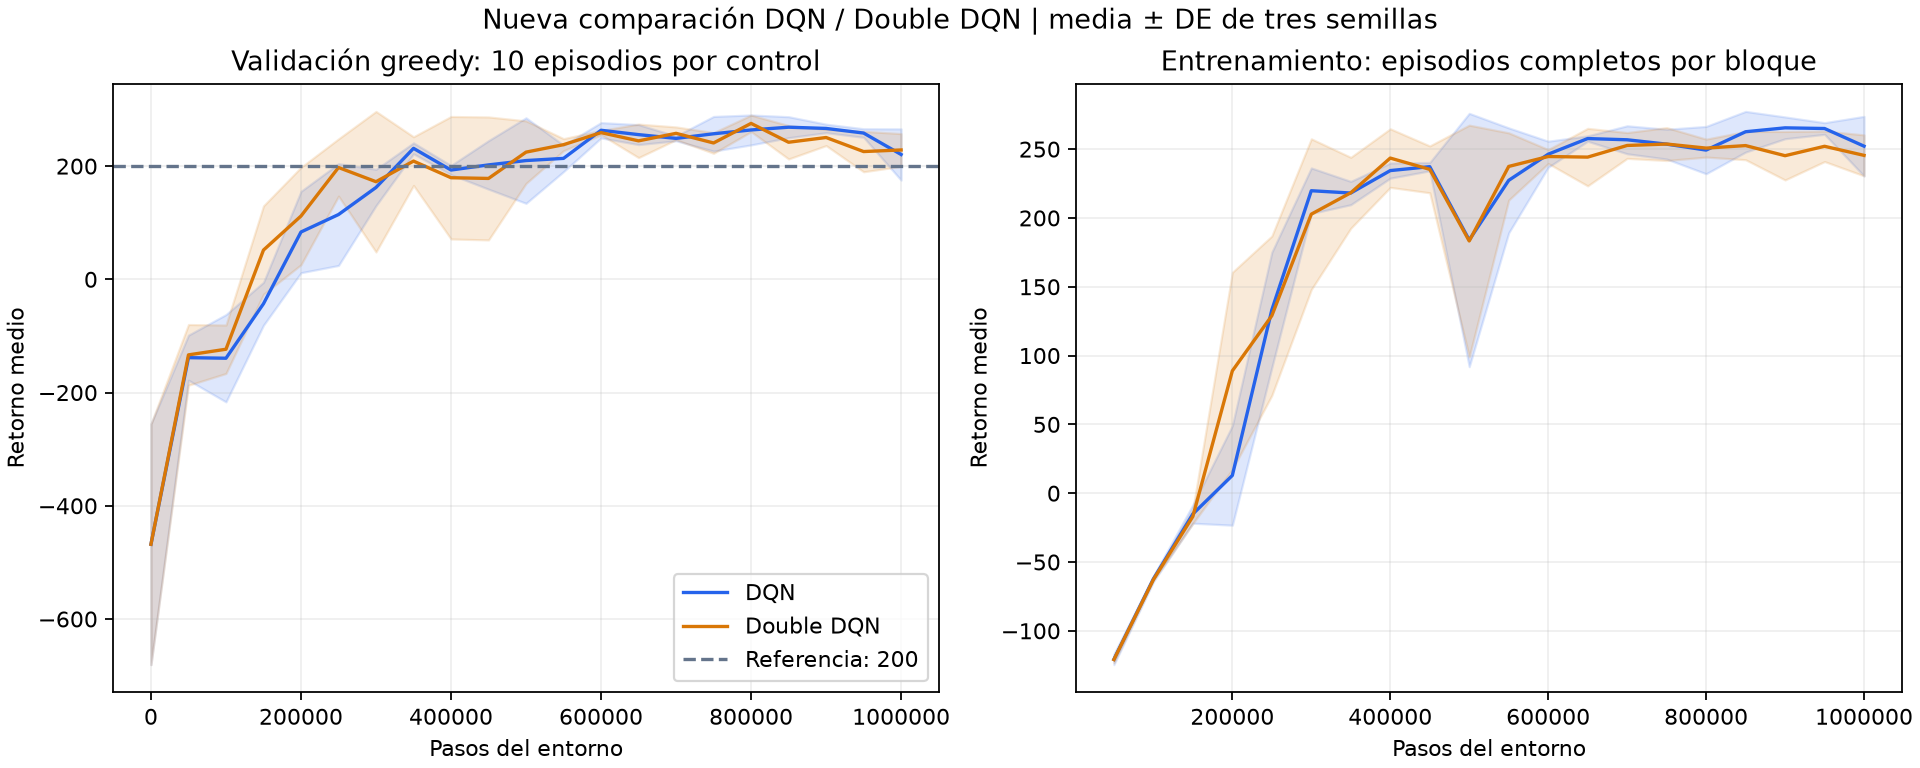

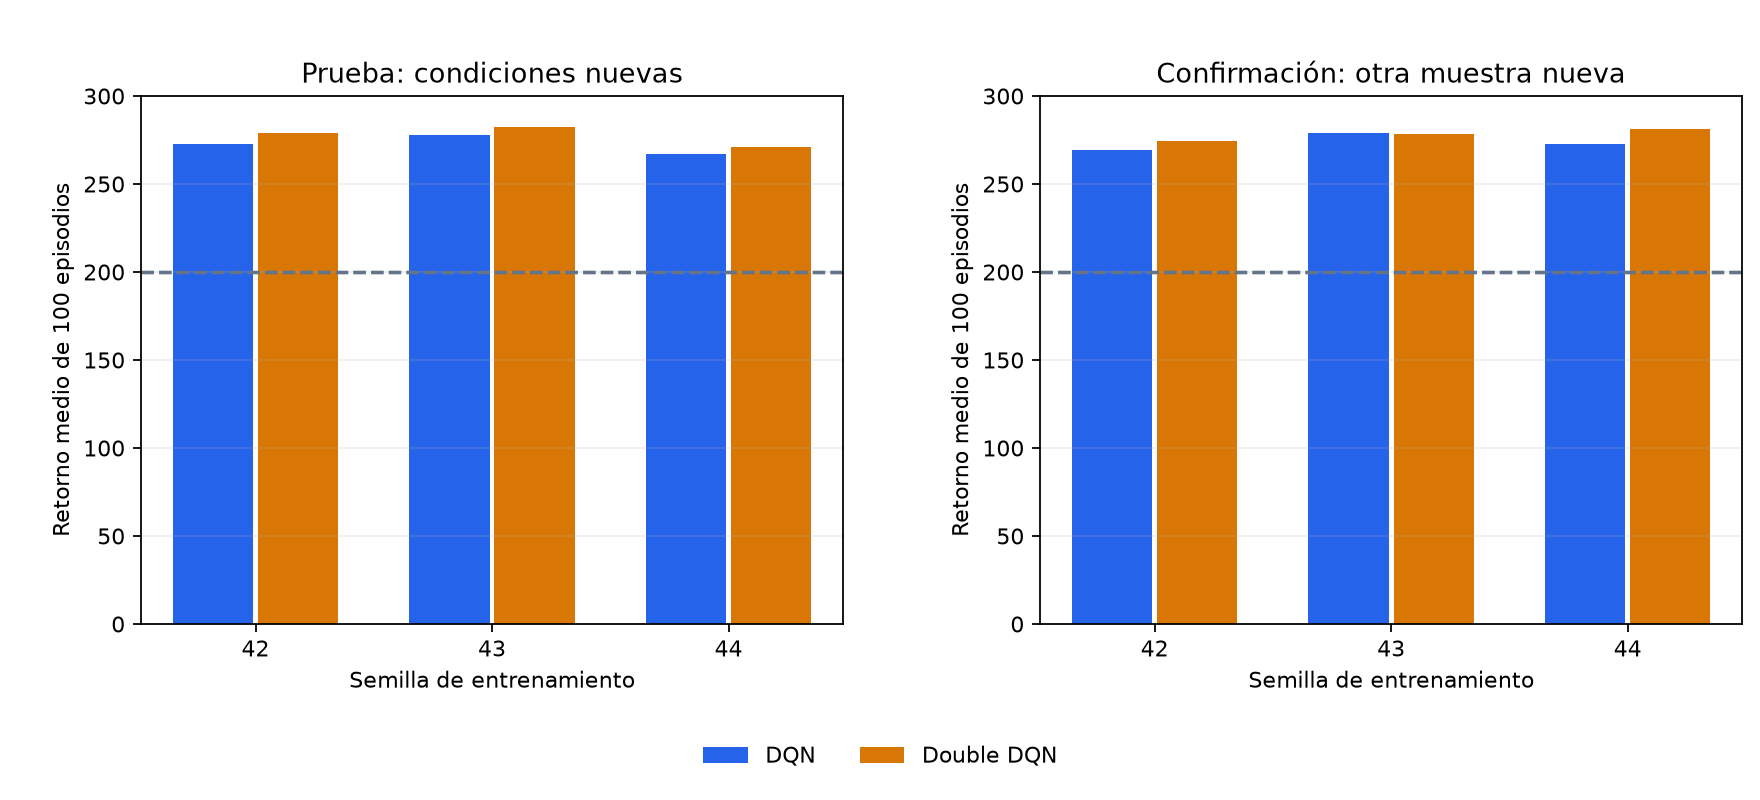

In [12]:
figura_mejora('learning')
figura_mejora('tests')

In [13]:
discusion_mejora()

# Mejora de Tier 2 y Tier 3

## Protocolo y alcance

Presupuesto completo: 1000000 pasos por modelo; semillas [42, 43, 44]. Ambos algoritmos usan los mismos parámetros.
Parámetros: {'hidden_widths': [128, 128], 'learning_rate': 0.00063, 'loss': 'smooth_l1', 'gamma': 0.99, 'buffer_size': 100000, 'batch_size': 128, 'learning_starts': 5000, 'train_every': 4, 'gradient_steps': 1, 'target_sync_every': 1000, 'epsilon_decay_steps': 200000, 'epsilon_end': 0.05}. Calendario de tasa: {'decay_start': 300000, 'decay_end': 800000, 'final': 5e-05}.
Se guardan los pesos del final del entrenamiento y, por separado, el checkpoint con mayor media de validación confirmada en 100 episodios.
Validación: base 30000000; controles de 10 cada 50000 pasos. Se amplían a 100 cuando alcanzan 200 y siempre al final.
Prueba y confirmación: bases 40000000 y 50000000, 100 episodios por modelo en cada una. No intervienen en la selección.
Los modelos seleccionados se cargan del disco y reproducen exactamente sus 100 retornos de validación antes de probarlos.
Las curvas describen la red durante el entrenamiento; en el último control usan los primeros diez episodios. Las tablas de prueba corresponden al checkpoint seleccionado, que puede ser anterior al último paso.
El paso seleccionado no es un ahorro de entrenamiento: cada modelo consume todo el presupuesto antes de probarse.
Los estudios originales de 500000 pasos y sus resultados negativos se conservan. Esta ronda cambia conjuntamente el presupuesto y varios ajustes; no permite atribuir la mejora a uno solo.
No se cambian recompensas, límite de 1000 pasos del entorno ni semillas de entrenamiento.

Grupos completos: 2/2. Objetivo de ambas pruebas, tres semillas por método: True.

| Método | Semilla | Primer umbral validado | Paso seleccionado | Validación 100 | Prueba 100 | Confirmación 100 |
|---|---:|---:|---:|---:|---:|---:|
| base | 42 | 350000 | 500000 | 270.64 | 272.70 | 269.08 |
| base | 43 | 250000 | 850000 | 278.32 | 277.61 | 279.00 |
| base | 44 | 450000 | 850000 | 276.82 | 267.25 | 273.00 |
| double | 42 | 450000 | 950000 | 276.93 | 278.71 | 274.18 |
| double | 43 | 200000 | 400000 | 281.67 | 282.33 | 278.67 |
| double | 44 | 300000 | 800000 | 281.72 | 271.08 | 281.35 |

| Método | Media prueba ± DE | Media confirmación ± DE | Semillas ≥200 en ambas |
|---|---:|---:|---:|
| base | 272.52 ± 4.23 | 273.69 ± 4.08 | 3/3 |
| double | 277.37 ± 4.69 | 278.07 ± 2.96 | 3/3 |

Double menos DQN en prueba: +4.85; diferencias por semilla +6.00, +4.72, +3.83.
La diferencia describe estas tres repeticiones; no demuestra una superioridad universal de un método.
Alcanzar 200 en las tres semillas no garantiza éxito para cualquier inicialización futura. La DE es entre medias de semillas (ddof=0).

## Tiempo y reproducción

Tiempos por modelo en summary.json: entrenamiento excluye validación/prueba; total las incluye. Las semillas comparten CPU, un hilo PyTorch por proceso. No es un benchmark aislado.

| Método | Entrenamiento medio (s) | Total medio (s) |
|---|---:|---:|
| base | 1898.6 | 2185.2 |
| double | 2002.5 | 2309.9 |

Equipo: AMD64 Family 23 Model 24 Stepping 1, AuthenticAMD; 8 procesadores lógicos, CPU, un hilo por proceso. Windows-11-10.0.26200-SP0.
Python 3.12.0; paquetes {'torch': '2.15.0+cpu', 'numpy': '2.5.4', 'gymnasium': '1.4.0', 'Box2D': '2.3.10'}.

Reproducir esta ronda: python -m experiments.mejorar_tier23 --output results/reproduccion_mejora
Regenerar figuras sin entrenar: python -m experiments.resumir_mejora --root results/tier23_mejora_v1
Los modelos incluyen versiones de paquetes, hardware y huellas de código en config.json.
Referencia de parámetros: https://github.com/DLR-RM/rl-baselines3-zoo/blob/master/hyperparams/dqn.yml


### Repetir la nueva comparación (opcional, entrenamiento largo)

La celda está desactivada. Si se activa, ejecuta los seis modelos en una carpeta
nueva con CONFIG_MEJORA. Mantén las semillas 42/43/44 para este protocolo.
Ambos métodos usan el mismo presupuesto. La prueba solo se abre si todos los modelos
alcanzan el margen predefinido de validación; de lo contrario se informa que falta ajustar.

In [14]:
EJECUTAR_MEJORA = False
if EJECUTAR_MEJORA:
    from datetime import datetime
    import subprocess
    destino = ROOT / 'results/notebook_lunar' / datetime.now().strftime('mejora_%Y%m%d_%H%M%S_%f')
    destino.mkdir(parents=True, exist_ok=False)
    archivo = destino / 'requested_config.json'
    archivo.write_text(json.dumps(CONFIG_MEJORA, indent=2), encoding='utf-8')
    subprocess.run([sys.executable, '-m', 'experiments.mejorar_tier23',
                    '--config', str(archivo), '--output', str(destino)], cwd=ROOT, check=True)
else:
    print('Entrenamiento de mejora desactivado: solo se consultan resultados guardados.')

Entrenamiento de mejora desactivado: solo se consultan resultados guardados.


## Estudios iniciales: 500000 pasos

Las tablas usan 100 episodios por modelo. La DE describe variación entre las medias de
las tres semillas. Las curvas usan 10 episodios por control, incluidos los primeros 10
al inicio/final; por ello su último punto puede diferir de la tabla final de 100.
Editar CONFIG no cambia estos resultados: corresponden al protocolo guardado en OUTPUT.

In [15]:
filas = resumen(tier=3)

Tier 3: 2/2 grupos completos; cada uno debe incluir tres semillas.


Grupo,Media final ± DE,Semillas ≥200,Entrenamiento
base,194.77 ± 34.50,1/3,1027.4 s
double,122.85 ± 91.26,1/3,910.4 s


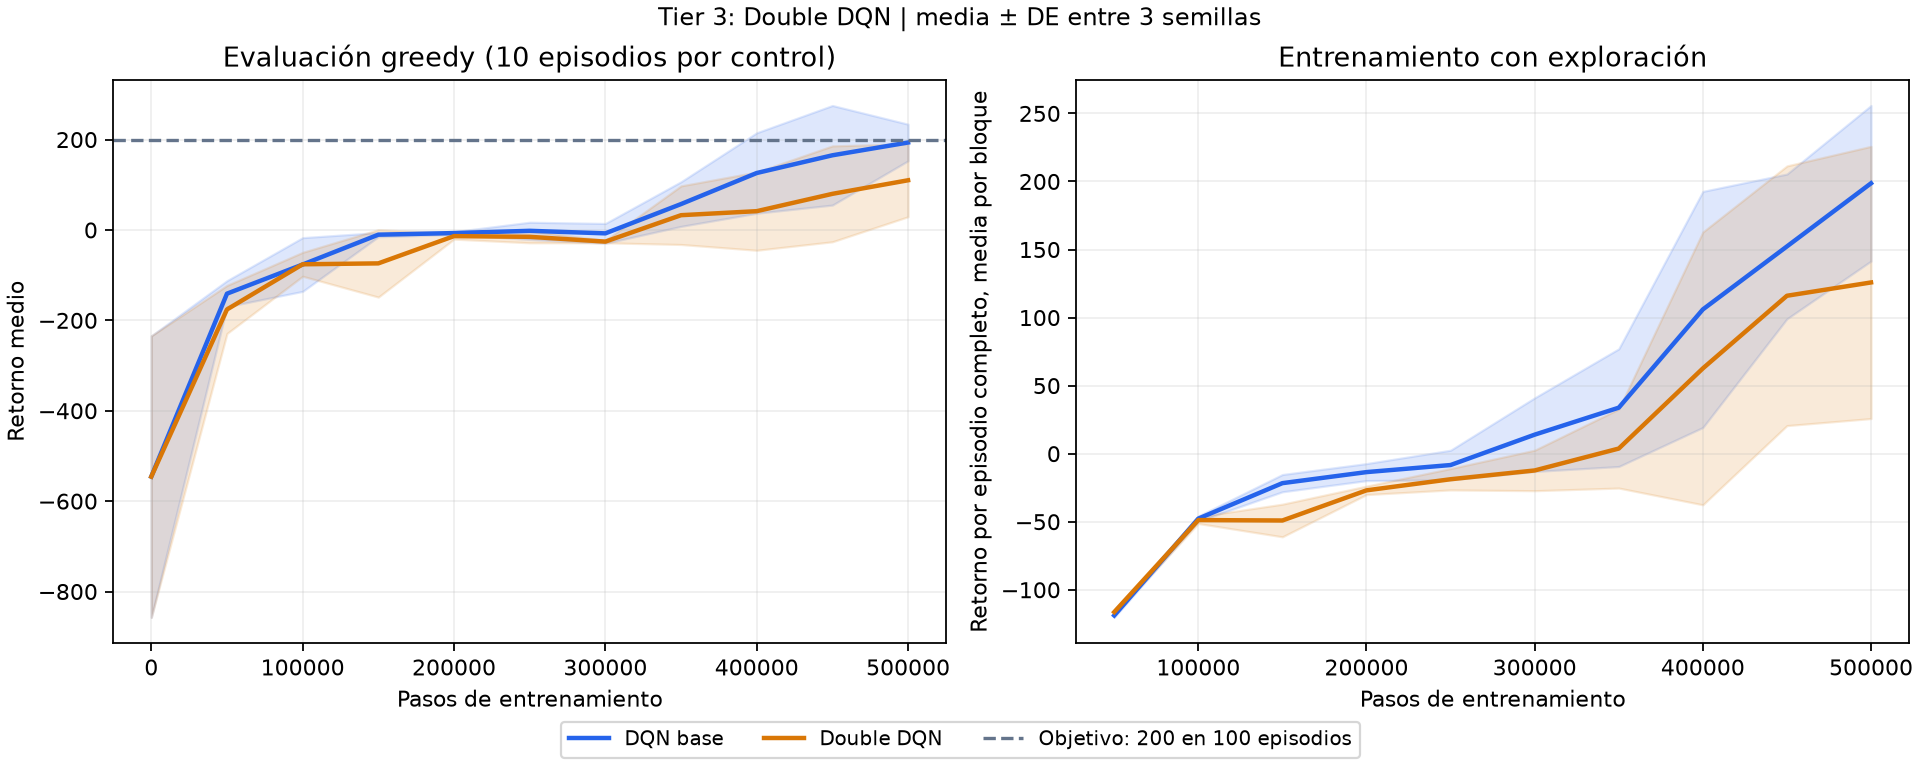

In [16]:
figura('double_dqn')

In [17]:
discusion(tier=3)

# Tier 3 — LunarLander-v3

## Protocolo

Entorno LunarLander-v3, acciones discretas, parámetros {'continuous': False, 'enable_wind': False, 'gravity': -10.0}.
Presupuesto 500000 pasos, semillas [42, 43, 44], evaluación greedy cada 50000 pasos.
Base: red 8 → 128 → 128 → 4, Adam lr=0.0005, pérdida smooth_l1, gamma=0.99.
Replay 100000, lote 64, ajustes desde 5000 pasos: 1 ajuste cada 8 pasos; copia target cada 2000.
Exploración lineal de 1 a 0.05 en 150000 pasos, después constante. Evaluación sin exploración.
Controles de 10 episodios; inicio/final de 100 y confirmación de 100 cuando un control alcanza 200.
Se entregan modelos finales. No se elige el mejor checkpoint ni se descarta una semilla débil.
Las curvas usan los primeros 10 episodios al inicio/final; las tablas finales usan los 100.
La banda es una DE entre las medias de las semillas (ddof=0), no un IC del 95%.
DQN base se reutiliza en los dos estudios, la ablación y Tier 3. No son entrenamientos adicionales independientes.
Todos los agentes son propios; la referencia SB3 Zoo solo orientó parámetros. No se importó un agente entrenado.
Errata del protocolo congelado: el texto descriptivo selection menciona 200000 por arrastre de un piloto. El campo steps, los bucles y los CSV usan 500000; no se cambia el protocolo histórico.

## Estado y resultados completos

Grupos completos: 2/2. No se informan ejecuciones parciales como resultados finales.

| Grupo | Media final ± DE | Retornos por semilla | Semillas ≥200 | Entrenamiento medio | Total medio con evaluación |
|---|---:|---|---:|---:|---:|
| base | 194.77 ± 34.50 | 166.40, 174.58, 243.33 | 1/3 | 1027.4 s | 1209.0 s |
| double | 122.85 ± 91.26 | 227.71, 5.26, 135.60 | 1/3 | 910.4 s | 1091.6 s |

La columna entrenamiento excluye evaluación; total la incluye. El total va desde la evaluación inicial hasta guardar los modelos, excluyendo arranque de Python y preparación inicial.
Los tratamientos se ejecutan en secuencia; sus semillas pueden correr en procesos paralelos, un hilo PyTorch por proceso.
Consultar execution.json: la primera semilla base comenzó con ejecución secuencial. Los tiempos no se interpretan como comparaciones aisladas de hardware.
Durante el trabajo se realizan verificaciones y mediciones de coste; estos tiempos de reloj describen esta máquina y no son benchmarks aislados.

## Tier 3 — Double DQN

Double DQN menos DQN base: -71.91 puntos de media final.
Diferencias emparejadas por semilla [42, 43, 44]: +61.31, -169.33, -107.73; mejora en 1/3.
La red online elige argmax; target valora esa acción. En DQN estándar target selecciona y valora.
Se mantienen parámetros, inicializaciones por semilla, presupuesto y evaluación del baseline.
Double DQN no aumenta la media final observada. Separar selección y valoración no garantiza una política mejor con este presupuesto.
La propuesta busca reducir sesgo de sobreestimación; no garantiza mejorar cada entorno o cada semilla.

## Diagnóstico y límites

LunarLander tiene recompensas distintas de CartPole. No se usa el límite Q≤100 del análisis anterior.
Los CSV registran pérdidas, extremos Q en 256 estados y una brecha de selección entre online y target.
Esa brecha no es el error Q frente al valor verdadero ni demuestra sobreestimación por sí sola.
Las semillas se usan durante el desarrollo; tres repeticiones son el mínimo, no una garantía universal.
La comparación causal de hiperparámetros depende de mantener el resto del protocolo; revisar config.json por modelo.
Tier 3 requiere comparar base y Double DQN con tres semillas y parámetros iguales.
La brecha entre redes se registra después de las copias programadas y puede ser cero por esa coincidencia temporal.

## Pasos hasta el umbral

- base: 42: 400000, 43: not reached, 44: 450000
- double: 42: 500000, 43: not reached, 44: not reached

## Estabilidad y pérdidas medidas

diagnostics.json resume la pérdida del último bloque y los valores Q de diagnóstico por modelo.
La pérdida mide ajuste al objetivo de bootstrap, no calidad de aterrizaje. Una pérdida menor no implica mayor retorno.
El mejor control de 100 solo se usa para describir la trayectoria, nunca para elegir los pesos entregados. No todos los controles intermedios se ampliaron a 100.
1 ejecuciones confirmaron ≥200 en un control anterior y terminaron por debajo de 200.
- base, semilla 42: mejor confirmación observada 240.06 a 400000 pasos; final 166.40.
La regresión es compatible con el aprendizaje sobre objetivos cambiantes y trayectorias distintas de replay/exploración; los registros por sí solos no aíslan una causa única.

Valores por semilla, en orden [42, 43, 44]. Pérdida: mediana del último bloque de entrenamiento; Q: máximo final en el banco de 256 estados aleatorios de cada semilla.
Ese banco no estima el valor verdadero de la política ni permite demostrar sobreestimación.

| Grupo | Medianas de pérdida | Máximos Q en el banco |
|---|---|---|
| base | 0.774, 0.274, 0.546 | 112.12, 113.70, 118.32 |
| double | 0.716, 0.116, 0.460 | 103.69, 109.54, 115.98 |

## Equipo y reproducción

Python 3.12.0; paquetes {'gymnasium': '1.4.0', 'numpy': '2.5.4', 'torch': '2.15.0+cpu', 'Box2D': '2.3.10'}; Windows-11-10.0.26200-SP0.
CPU AMD64 Family 23 Model 24 Stepping 1, AuthenticAMD, 8 procesadores lógicos; un hilo, sin GPU.
Parámetros: configs/tier23_lunarlander.json. Notebooks: Tier2_LunarLander.ipynb y Tier3_DoubleDQN.ipynb.

## Evaluación adicional con nuevos inicios

Las condiciones iniciales se fijaron en el protocolo antes de entrenar. No se utilizan para reajustar parámetros ni escoger una semilla.
Base y Double pertenecen a la comparación predefinida. También se evalúa el DQN de mayor media de desarrollo de Tier 2: la elección de esa variante es posterior a desarrollo y está registrada en new_protocol.json.
Son nuevas condiciones iniciales de la misma distribución, no nuevos entrenamientos.

| Grupo | Media nueva ± DE | Semillas ≥200 |
|---|---:|---:|
| base | 203.84 ± 32.62 | 1/3 |
| double | 124.13 ± 96.54 | 1/3 |

## Finalización de los episodios de desarrollo

Resting indica que el cuerpo quedó en reposo; body_contact indica contacto del cuerpo; time_limit es corte por tiempo.
Estos conteos describen comportamiento. El criterio del proyecto sigue siendo la recompensa media, no solo el contacto con el suelo.

La clasificación prioriza corte por tiempo, contacto del cuerpo, fuera del área y reposo; algunos eventos físicos pueden coincidir.

| Grupo | Cuerpo/contacto | Fuera del área | Reposo | Límite de tiempo | Otros |
|---|---:|---:|---:|---:|---:|
| base | 2 | 0 | 187 | 111 | 0 |
| double | 12 | 0 | 118 | 170 | 0 |

Para los grupos cuya media final queda por debajo de 200, los finales observados ayudan a concretar el fallo:
- base: reposo del cuerpo en 187/300 episodios, la finalización más frecuente. Debe leerse junto con el retorno: reposar no basta para obtener ≥200, y alcanzar el límite no confirma un aterrizaje.
- double: agotamiento del límite de tiempo en 170/300 episodios, la finalización más frecuente. Debe leerse junto con el retorno: reposar no basta para obtener ≥200, y alcanzar el límite no confirma un aterrizaje.
Son síntomas observados de las políticas finales; no identifican por sí solos una causa única del proceso de aprendizaje.

## Referencias

- Gymnasium LunarLander: https://gymnasium.farama.org/environments/box2d/lunar_lander/
- Referencia de parámetros: https://github.com/DLR-RM/rl-baselines3-zoo/blob/master/hyperparams/dqn.yml
- Double DQN: van Hasselt, Guez y Silver, https://arxiv.org/abs/1509.06461


## Ver la nave dentro del notebook

Se muestra el primer episodio de la semilla escogida. No aprende durante la animación.
La recompensa de un episodio no sustituye la evaluación de 100 ni la repetición de semillas.

In [18]:
VER_NAVE = False
GRUPO = 'double'
SEMILLA = 42  # 42, 43 o 44
if VER_NAVE:
    demostrar(GRUPO, SEMILLA, inline=True)
else:
    print('Cambia VER_NAVE a True para generar la animación.')

Cambia VER_NAVE a True para generar la animación.


## Preguntas para la defensa

- ¿Qué observan las ocho entradas y qué representan las cuatro salidas Q?
- ¿Cómo distinguimos entrenar de evaluar? ¿Por qué tres semillas y 100 episodios finales?
- ¿Qué cambia exactamente en cada comparación y qué permanece igual?
- ¿Qué evidencia dan las curvas, la variación y los resultados negativos?
- ¿Por qué un Q grande o una brecha entre redes no prueba por sí sola sobreestimación verdadera?

El artículo final debe incorporar los resultados e interpretación. Los notebooks no sustituyen
el paper ni la defensa. Uso de IA: `report/uso_ia.md`.

Referencias: [Gymnasium](https://gymnasium.farama.org/environments/box2d/lunar_lander/),
[parámetros de referencia](https://github.com/DLR-RM/rl-baselines3-zoo/blob/master/hyperparams/dqn.yml),
[Double DQN](https://arxiv.org/abs/1509.06461).